#  <span style="color:#C133FF"> Loading data from all participants for visualization purposes !</span> 

In [1]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import sys
import pandas as pd
import os
import json
import time

In [1]:
participant_id = "dB0_035"

### <span style="color:green"> Expiration B0 maps </span> 



In [16]:
# Load metrics per participant from the CSV
dmod_exp_metrics35_data = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_035\exp\sub-2_OLD_Aspire_DEMOD_EXP_mean_per_level_1_15.csv")["dmod_B0_Hz"]
dmod_exp_metrics33_data = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\exp\sub-1_OLD_Aspire_DEMOD_EXP_mean_per_level_1_15.csv")["dmod_B0_Hz"]
dmod_exp_metricsx27_data = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\chi_027\niftis\meGRE_EXP\sub-16_clearswi_DEMOD_EXP_mean_per_level_1_15.csv")["dmod_B0_Hz"]

### <span style="color:red"> Inspiration B0 maps </span> 

In [17]:
# Load metrics per participant from the CSV
# Load metrics per participant from the CSV
dmod_insp_metrics35_data = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_035\insp\sub-2_OLD_Aspire_DEMOD_INSP_mean_per_level_1_15.csv")["dmod_B0_Hz"]
dmod_insp_metrics33_data = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\insp\sub-1_OLD_Aspire_DEMOD_INSP_mean_per_level_1_15.csv")["dmod_B0_Hz"]
dmod_insp_metricsx27_data = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\chi_027\niftis\meGRE_INSP\sub-16_clearswi_DEMOD_INSP_mean_per_level_1_15.csv")["dmod_B0_Hz"]

### <span style="color:#C28AD1"> Average Insp and Exp metrics</span> 

In [19]:
dmod_avg_resp33 = (dmod_exp_metrics33_data+dmod_insp_metrics33_data)/2
dmod_avg_resp35 = (dmod_exp_metrics35_data+dmod_insp_metrics35_data)/2
dmod_avg_respx27 = (dmod_exp_metricsx27_data+dmod_insp_metricsx27_data)/2

In [6]:
vertebrae_levelsC2_T7 = ['C2','C3','C4', 'C5', 'C6', 'C7', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7'] # From 1 to 15

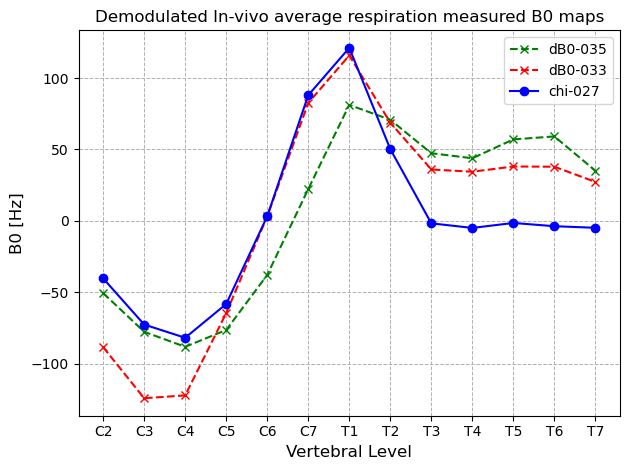

In [20]:
plt.plot(vertebrae_levelsC2_T7, dmod_avg_resp35, marker = 'x', linestyle = '--', label = "dB0-035", color = "green")
plt.plot(vertebrae_levelsC2_T7, dmod_avg_resp33, marker = 'x', linestyle = '--', label = "dB0-033", color = "red")
plt.plot(vertebrae_levelsC2_T7, dmod_avg_respx27, marker = 'o', linestyle = '-', label = "chi-027", color = "blue")

plt.title(f"Demodulated In-vivo average respiration measured B0 maps")
plt.xlabel('Vertebral Level', fontsize=12)
plt.ylabel('B0 [Hz]', fontsize=12)
plt.legend()
# Customize grid and display
plt.grid(True, which='both', linestyle='--', linewidth=0.7)
plt.tight_layout()

# Show the plot
plt.show()

### <span style="color:#14EFFA"> Initial B0 and chi-fitting results </span>

You need to be sure that the csv you are loading has the results from the fit versus (a) average respiration, (b) expiration, or (c) inspiration!

In [9]:
path_to_fit_results_35_csv = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_035\sub-02_lung_chi_avg_respiration_unconstrained_fit.csv"
fit_results_df35 = pd.read_csv(path_to_fit_results_35_csv)

vertebrae_levels_plot = (
    fit_results_df35["VertebralLevel"].to_numpy()
)

measured_profile_plot35 = (
    fit_results_df35["MeasuredProfile_Hz"].to_numpy()
)

profile_unconstrained_plot35 = (
    fit_results_df35["FittedProfile_Hz"].to_numpy()
)

chi_lung_plot35 = (
    fit_results_df35["FittedLungChi_ppm"].iloc[0]
)

rmse_plot35 = (
    fit_results_df35["FitRMSE_Hz"].iloc[0]
)

In [10]:
path_to_fit_results_x27_csv = r"R:\soothsayer\msc_data\chi_fitting\chi_027\sub-16_lung_chi_avg_respiration_unconstrained_fit.csv"
fit_results_dfx27 = pd.read_csv(path_to_fit_results_x27_csv)

measured_profile_plotx27 = (
    fit_results_dfx27["MeasuredProfile_Hz"].to_numpy()
)

profile_unconstrained_plotx27 = (
    fit_results_dfx27["FittedProfile_Hz"].to_numpy()
)

chi_lung_plotx27 = (
    fit_results_dfx27["FittedLungChi_ppm"].iloc[0]
)

rmse_plotx27 = (
    fit_results_dfx27["FitRMSE_Hz"].iloc[0]
)

In [23]:
path_to_fit_results_33_csv = r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sub-01_lung_chi_avg_respiration_unconstrained_fit.csv"
fit_results_df33 = pd.read_csv(path_to_fit_results_33_csv)

measured_profile_plot33 = (
    fit_results_df33["MeasuredProfile_Hz"].to_numpy()
)

profile_unconstrained_plot33 = (
    fit_results_df33["FittedProfile_Hz"].to_numpy()
)

chi_lung_plot33 = (
    fit_results_df33["FittedLungChi_ppm"].iloc[0]
)

rmse_plotx33 = (
    fit_results_df33["FitRMSE_Hz"].iloc[0]
)

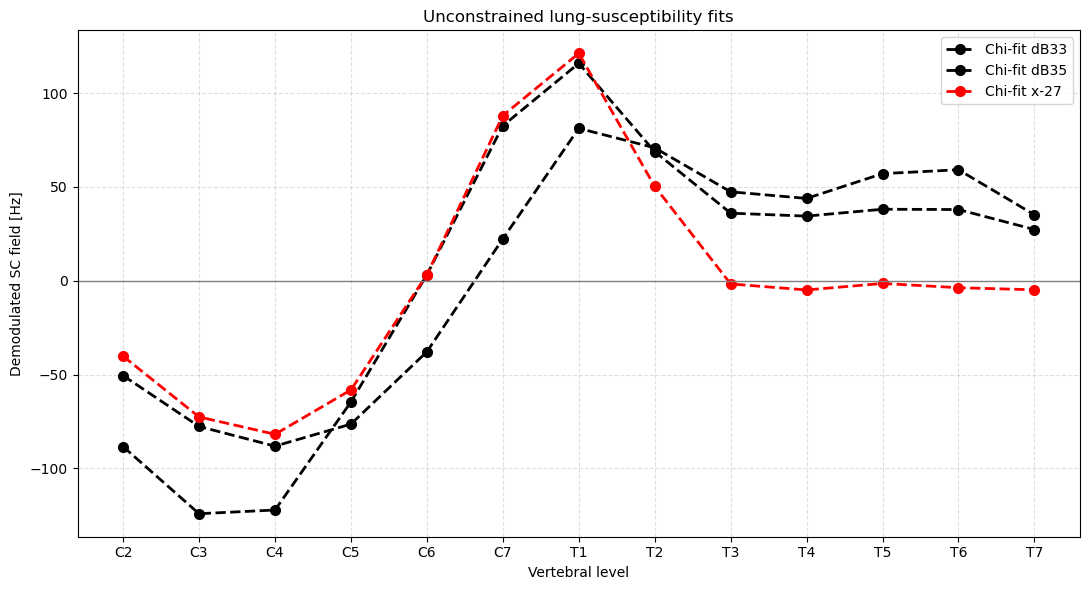

: 

In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    vertebrae_levels_plot,
    measured_profile_plot33,
    marker="o",
    markersize=7,
    linestyle="--",
    linewidth=2,
    color="black",
    label="Chi-fit dB33",
)

ax.plot(
    vertebrae_levels_plot,
    measured_profile_plot35,
    marker="o",
    markersize=7,
    linestyle="--",
    linewidth=2,
    color="black",
    label="Chi-fit dB35",
)

ax.plot(
    vertebrae_levels_plot,
    measured_profile_plotx27,
    marker="o",
    markersize=7,
    linestyle="--",
    linewidth=2,
    color="red",
    label="Chi-fit x-27",
)


ax.axhline(
    0,
    color="gray",
    linewidth=1,
)

ax.set_xlabel("Vertebral level")
ax.set_ylabel("Demodulated SC field [Hz]")

ax.set_title(
    "Unconstrained "
    "lung-susceptibility fits"
)

ax.grid(
    True,
    linestyle="--",
    alpha=0.4,
)

ax.legend()

fig.tight_layout()
plt.show()

### Debug

In [52]:
selected_metric_mask = np.isin(
    metric_sim_mask,
    [
        vertebra_label_map[level]
        for level in vertebrae_levels_opt
    ],
)

print(
    "All simulation demodulation voxels:",
    np.count_nonzero(dmod_sim_mask == 1),
)

print(
    "Selected C2-T7 metric voxels:",
    np.count_nonzero(selected_metric_mask),
)

print(
    "Demodulation voxels outside C2-T7:",
    np.count_nonzero(
        (dmod_sim_mask == 1)
        & (~selected_metric_mask)
    ),
)

print(
    "Mean measured profile:",
    np.mean(measured_profile),
)

print(
    "Mean simulated fitted profile:",
    np.mean(profile_unconstrained),
)

print(
    "Mean residual:",
    np.mean(
        profile_unconstrained - measured_profile
    ),
)

All simulation demodulation voxels: 24855
Selected C2-T7 metric voxels: 12429
Demodulation voxels outside C2-T7: 12426
Mean measured profile: -0.0387564781503993
Mean simulated fitted profile: 5.107191003709157
Mean residual: 5.14594748185956


In [56]:
print(
    "Least-squares orthogonality:",
    np.dot(lung_response, residual_unconstrained)
)

Least-squares orthogonality: -3.019806626980426e-13


The closer it is to zero then it means the LS results is truly the LSQ minimum for the curred fixed_profile vs lung_response